In [1]:
import pandas as pd
from pathlib import Path
from urllib.request import urlretrieve

folder = Path('data/sms_spam_indonesia')
folder.mkdir(parents=True, exist_ok=True)
file = folder / 'dataset_sms_spam_v1.csv'

if not file.exists():
    url = (
        'https://raw.githubusercontent.com/Andikazidanef15/'
        'Sentiment-Analysis-on-Indonesian-SMS-Dataset/main/'
        'dataset_sms_spam_v1.csv'
    )
    urlretrieve(url, file)

data = pd.read_csv(file).rename(
    columns={'Teks': 'teks', 'label': 'label_asli'}
)

data['label'] = data['label_asli'].map(
    {0: 'normal', 1: 'spam', 2: 'spam'}
)

data.head()

,teks,label_asli,label
0,[PROMO] Beli paket Flash mulai 1GB di MY TELKO...,2,spam
1,2.5 GB/30 hari hanya Rp 35 Ribu Spesial buat A...,2,spam
2,"2016-07-08 11:47:11.Plg Yth, sisa kuota Flash ...",2,spam
3,"2016-08-07 11:29:47.Plg Yth, sisa kuota Flash ...",2,spam
4,4.5GB/30 hari hanya Rp 55 Ribu Spesial buat an...,2,spam


In [2]:
print('Ukuran data:', data.shape)
print('Nilai kosong:')
print(data.isna().sum())
print('Jumlah label:')
print(data['label'].value_counts())

Ukuran data: (1143, 3)
Nilai kosong:
teks          0
label_asli    0
label         0
dtype: int64
Jumlah label:
label
spam      574
normal    569
Name: count, dtype: int64


In [3]:
import re

data['huruf_kecil'] = data['teks'].str.lower()

data['bersih'] = data['huruf_kecil'].str.replace(
    r'[^a-z0-9\s]', ' ', regex=True
)

data['bersih'] = data['bersih'].str.replace(
    r'\s+', ' ', regex=True
).str.strip()

data[['teks', 'bersih']].head()

,teks,bersih
0,[PROMO] Beli paket Flash mulai 1GB di MY TELKO...,promo beli paket flash mulai 1gb di my telkoms...
1,2.5 GB/30 hari hanya Rp 35 Ribu Spesial buat A...,2 5 gb 30 hari hanya rp 35 ribu spesial buat a...
2,"2016-07-08 11:47:11.Plg Yth, sisa kuota Flash ...",2016 07 08 11 47 11 plg yth sisa kuota flash a...
3,"2016-08-07 11:29:47.Plg Yth, sisa kuota Flash ...",2016 08 07 11 29 47 plg yth sisa kuota flash a...
4,4.5GB/30 hari hanya Rp 55 Ribu Spesial buat an...,4 5gb 30 hari hanya rp 55 ribu spesial buat an...


In [4]:
contoh = data.loc[0, 'bersih']
token = contoh.split()

print('Teks:', contoh)
print('Token:', token)

Teks: promo beli paket flash mulai 1gb di my telkomsel app dpt extra kuota 2gb 4g lte dan extra nelpon hingga 100mnt 1hr buruan cek di tsel me mytsel1 s k
Token: ['promo', 'beli', 'paket', 'flash', 'mulai', '1gb', 'di', 'my', 'telkomsel', 'app', 'dpt', 'extra', 'kuota', '2gb', '4g', 'lte', 'dan', 'extra', 'nelpon', 'hingga', '100mnt', '1hr', 'buruan', 'cek', 'di', 'tsel', 'me', 'mytsel1', 's', 'k']


In [9]:
!pip install Sastrawi

from Sastrawi.StopWordRemover.StopWordRemoverFactory import (
    StopWordRemoverFactory
)

stopwords = set(StopWordRemoverFactory().get_stop_words())
stopwords = stopwords - {'tidak', 'bukan', 'jangan', 'belum'}

token_penting = []
for kata in token:
    if kata not in stopwords:
        token_penting.append(kata)

print(token_penting)

['promo', 'beli', 'paket', 'flash', 'mulai', '1gb', 'my', 'telkomsel', 'app', 'dpt', 'extra', 'kuota', '2gb', '4g', 'lte', 'extra', 'nelpon', 'hingga', '100mnt', '1hr', 'buruan', 'cek', 'tsel', 'me', 'mytsel1', 's', 'k']


In [10]:
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

stemmer = StemmerFactory().create_stemmer()
hasil_stem = [stemmer.stem(kata) for kata in token_penting]

print('Sebelum:', token_penting)
print('Sesudah:', hasil_stem)

Sebelum: ['promo', 'beli', 'paket', 'flash', 'mulai', '1gb', 'my', 'telkomsel', 'app', 'dpt', 'extra', 'kuota', '2gb', '4g', 'lte', 'extra', 'nelpon', 'hingga', '100mnt', '1hr', 'buruan', 'cek', 'tsel', 'me', 'mytsel1', 's', 'k']
Sesudah: ['promo', 'beli', 'paket', 'flash', 'mulai', '1gb', 'my', 'telkomsel', 'app', 'dpt', 'extra', 'kuota', '2gb', '4g', 'lte', 'extra', 'nelpon', 'hingga', '100mnt', '1hr', 'buru', 'cek', 'tsel', 'me', 'mytsel1', 's', 'k']


In [11]:
from collections import Counter
import matplotlib.pyplot as plt

semua_kata = ' '.join(data['bersih']).split()
frekuensi = Counter(
    kata for kata in semua_kata if kata not in stopwords
)

print(frekuensi.most_common(10))

[('info', 226), ('www', 180), ('com', 170), ('pin', 167), ('no', 165), ('hadiah', 133), ('yg', 130), ('sms', 127), ('aku', 127), ('mau', 125)]


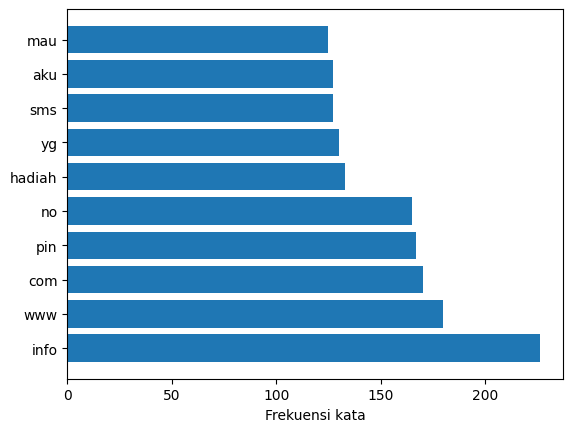

In [12]:
kata, jumlah = zip(*frekuensi.most_common(10))

plt.barh(kata, jumlah)
plt.xlabel('Frekuensi kata')
plt.show()

In [13]:
from sklearn.feature_extraction.text import CountVectorizer

dokumen = data['bersih'].head(5)

count = CountVectorizer()
matriks_count = count.fit_transform(dokumen)

pd.DataFrame(
    matriks_count.toarray(),
    columns=count.get_feature_names_out()
)

,07,08,100mnt,11,1gb,1hr,2015,2016,29,2gb,...,sekarang,sisa,skb,spesial,telkomsel,terpilih,tsel,utk,yang,yth
0,0,0,1,0,1,1,0,0,0,1,...,0,0,0,0,1,0,1,0,0,0
1,0,0,0,0,0,0,1,0,0,0,...,2,0,0,1,0,1,0,0,1,0
2,1,1,0,2,0,0,0,1,0,0,...,0,1,0,0,0,0,2,1,0,1
3,1,1,0,1,0,0,0,1,1,0,...,0,1,0,0,0,0,2,1,0,1
4,0,0,0,0,0,0,0,0,0,0,...,1,0,1,1,0,1,0,0,1,0


In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()
matriks_tfidf = tfidf.fit_transform(dokumen)

pd.DataFrame(
    matriks_tfidf.toarray(),
    columns=tfidf.get_feature_names_out()
).round(2)

,07,08,100mnt,11,1gb,1hr,2015,2016,29,2gb,...,sekarang,sisa,skb,spesial,telkomsel,terpilih,tsel,utk,yang,yth
0,0.00,0.00,0.2,0.00,0.2,0.2,0.00,0.00,0.00,0.2,...,0.00,0.00,0.00,0.00,0.2,0.00,0.14,0.00,0.00,0.00
1,0.00,0.00,0.0,0.00,0.0,0.0,0.21,0.00,0.00,0.0,...,0.34,0.00,0.00,0.17,0.0,0.17,0.00,0.00,0.17,0.00
2,0.18,0.18,0.0,0.35,0.0,0.0,0.00,0.18,0.00,0.0,...,0.00,0.18,0.00,0.00,0.0,0.00,0.29,0.18,0.00,0.18
3,0.18,0.18,0.0,0.18,0.0,0.0,0.00,0.18,0.22,0.0,...,0.00,0.18,0.00,0.00,0.0,0.00,0.30,0.18,0.00,0.18
4,0.00,0.00,0.0,0.00,0.0,0.0,0.00,0.00,0.00,0.0,...,0.22,0.00,0.27,0.22,0.0,0.22,0.00,0.00,0.22,0.00


TUGAS


In [30]:
data = "Kuliah cape-cape sambil kerja ini itu, eh pas lulus kalah sama orang yang paunya ordal nanti gajinya juga kecil. Ini semua gara gara pemerintah bangsat, sedih banget liat kondisi negeri sendiri ya allah lindungi WNI $#%$#$%*^$*$"
print("TEKS ASLI:")
print(data)

TEKS ASLI:
Kuliah cape-cape sambil kerja ini itu, eh pas lulus kalah sama orang yang paunya ordal nanti gajinya juga kecil. Ini semua gara gara pemerintah bangsat, sedih banget liat kondisi negeri sendiri ya allah lindungi WNI $#%$#$%*^$*$


In [31]:
#case folding
huruf_kecil = data.lower()
print("HURUF KECIL:")
print(huruf_kecil)


kata_bersih = re.sub(r'[^a-z0-9\s]', ' ', huruf_kecil)
kata_bersih = re.sub(r'\s+', ' ', kata_bersih).strip()
print("KATA BERsih:")
print(kata_bersih)

HURUF KECIL:
kuliah cape-cape sambil kerja ini itu, eh pas lulus kalah sama orang yang paunya ordal nanti gajinya juga kecil. ini semua gara gara pemerintah bangsat, sedih banget liat kondisi negeri sendiri ya allah lindungi wni $#%$#$%*^$*$
KATA BERsih:
kuliah cape cape sambil kerja ini itu eh pas lulus kalah sama orang yang paunya ordal nanti gajinya juga kecil ini semua gara gara pemerintah bangsat sedih banget liat kondisi negeri sendiri ya allah lindungi wni


In [32]:
#tokenisasi
token = kata_bersih.split()
print(token)

['kuliah', 'cape', 'cape', 'sambil', 'kerja', 'ini', 'itu', 'eh', 'pas', 'lulus', 'kalah', 'sama', 'orang', 'yang', 'paunya', 'ordal', 'nanti', 'gajinya', 'juga', 'kecil', 'ini', 'semua', 'gara', 'gara', 'pemerintah', 'bangsat', 'sedih', 'banget', 'liat', 'kondisi', 'negeri', 'sendiri', 'ya', 'allah', 'lindungi', 'wni']


In [33]:
#menghapus stopwords
stopwords = set(StopWordRemoverFactory().get_stop_words())

token_penting = [
    kata for kata in token if kata not in stopwords]

print("SETELAH STOPWORDS:")
print(token_penting)
print("Jumlah token:", len(token_penting))

SETELAH STOPWORDS:
['kuliah', 'cape', 'cape', 'kerja', 'eh', 'pas', 'lulus', 'kalah', 'sama', 'orang', 'paunya', 'ordal', 'gajinya', 'kecil', 'semua', 'gara', 'gara', 'pemerintah', 'bangsat', 'sedih', 'banget', 'liat', 'kondisi', 'negeri', 'sendiri', 'allah', 'lindungi', 'wni']
Jumlah token: 28


In [34]:


#stemming

from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

stemmer = StemmerFactory().create_stemmer()
hasil_stem = [stemmer.stem(kata) for kata in token_penting]

print("SEBELUM STEMMING:")
print(token_penting)
print("SETELAH STEMMING:")
print(hasil_stem)

SEBELUM STEMMING:
['kuliah', 'cape', 'cape', 'kerja', 'eh', 'pas', 'lulus', 'kalah', 'sama', 'orang', 'paunya', 'ordal', 'gajinya', 'kecil', 'semua', 'gara', 'gara', 'pemerintah', 'bangsat', 'sedih', 'banget', 'liat', 'kondisi', 'negeri', 'sendiri', 'allah', 'lindungi', 'wni']
SETELAH STEMMING:
['kuliah', 'cape', 'cape', 'kerja', 'eh', 'pas', 'lulus', 'kalah', 'sama', 'orang', 'paunya', 'ordal', 'gaji', 'kecil', 'semua', 'gara', 'gara', 'perintah', 'bangsat', 'sedih', 'banget', 'liat', 'kondisi', 'negeri', 'sendiri', 'allah', 'lindung', 'wni']


In [35]:
#frekuensi kata
from collections import Counter

frekuensi = Counter(kata for kata in hasil_stem)
print(frekuensi.most_common(10))

[('cape', 2), ('gara', 2), ('kuliah', 1), ('kerja', 1), ('eh', 1), ('pas', 1), ('lulus', 1), ('kalah', 1), ('sama', 1), ('orang', 1)]
